### Build A Basic Chatbot With Langgraph(GRAPH API)

In [43]:
from typing import Annotated 

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [44]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

    ## add_messages - it is  a reducer that which does not replace the content of message variable instead it keeps the previous message and append a new message.
    ## Annoted - ## It's just a way to tell LangGraph: "for this field, use this rule when updating., The rule is "add_messages"

In [45]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [46]:
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [47]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000029587EC8B90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000029587EC9A90>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [48]:
llm=init_chat_model("openai/gpt-oss-20b", model_provider="groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000029587ABEC40>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000029587ABFCE0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [49]:
## Node Functionality
def chatbot(state:State):
    return {"messages" : [llm.invoke(state["messages"])]}

In [50]:
graph_builder = StateGraph(State)

## Adding node to graph
graph_builder.add_node("llmchatbot", chatbot)

## Adding the edges
graph_builder.add_edge(START, "llmchatbot") ## edge from start to llmchatbot
graph_builder.add_edge("llmchatbot", END)

## Compile the graph
graph = graph_builder.compile()

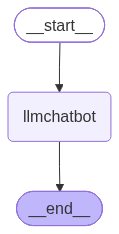

In [51]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [52]:
response=graph.invoke({"messages":"Hi"})

In [53]:
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ba5da7c4-65af-4c13-932a-e372f447a00f'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 72, 'total_tokens': 101, 'completion_time': 0.029236205, 'completion_tokens_details': {'reasoning_tokens': 11}, 'prompt_time': 0.003412702, 'prompt_tokens_details': None, 'queue_time': 0.367835237, 'total_time': 0.032648907}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_487ff4efc6', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20233-8548-7124-87b0-c5551f8a9b5d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 29, 'total_tokens': 101, 'output_token_details': {'reasoning': 11}})]}

In [54]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ba5da7c4-65af-4c13-932a-e372f447a00f'),
 AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 72, 'total_tokens': 101, 'completion_time': 0.029236205, 'completion_tokens_details': {'reasoning_tokens': 11}, 'prompt_time': 0.003412702, 'prompt_tokens_details': None, 'queue_time': 0.367835237, 'total_time': 0.032648907}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_487ff4efc6', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20233-8548-7124-87b0-c5551f8a9b5d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 29, 'total_tokens': 101, 'output_token_details': {'reasoning': 11}})]

In [55]:
response["messages"][-1]

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 72, 'total_tokens': 101, 'completion_time': 0.029236205, 'completion_tokens_details': {'reasoning_tokens': 11}, 'prompt_time': 0.003412702, 'prompt_tokens_details': None, 'queue_time': 0.367835237, 'total_time': 0.032648907}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_487ff4efc6', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20233-8548-7124-87b0-c5551f8a9b5d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 29, 'total_tokens': 101, 'output_token_details': {'reasoning': 11}})

In [56]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [57]:
for event in graph.stream({"messages" : "Hi! How are you"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I'm doing great—thanks for asking. How about you? Anything interesting on your mind today?


### Chatbot With Tool

In [58]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [59]:
from langchain_tavily import TavilySearch

## tool 1 - tavily that makes a google search.
tool = TavilySearch(max_results=2)
tool.invoke("What is langGraph")

{'query': 'What is langGraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://medium.com/@kyletran77/langgraph-explained-for-beginners-81521e243076',
   'title': 'LangGraph Explained for Beginners',
   'score': 0.8590736,
   'content': 'LangGraph brings workflow primitives to the world of LLM-based systems. By modeling computation as nodes, transitions as edges, and leveraging a persistent StateGraph, you can build adaptive, iterative, and production-ready AI assistants such as a deep research assistant that searches, validates, extracts, and synthesizes knowledge across multiple sources. The framework frees you from manually orchestrating scripts and lets you design intelligent workflows that behave more like human [...] In traditional code you would write separate scripts for searching, looping through links, scraping, scoring, filtering, and synthesizing reports while managing the orchestration yourself. With LangGraph, you can express ea

In [60]:
## tool 2 - Custom multipky function
def multiply(a:int, b:int)->int:
    """Multiply a and b

    Args:
    a (int): first int
    b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [61]:
tools = [tool, multiply]

In [62]:
## binding tools with llm

llm_with_tool = llm.bind_tools(tools)

In [63]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000029587ABEC40>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000029587ABFCE0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for co

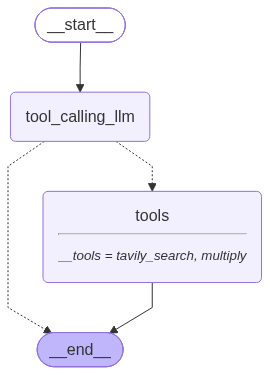

In [ ]:
## StateGrpah - Graph API
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State): ## state class we have previously defined at the start of this notebook.
    return {"messages" : [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


## Connecting the edges with node
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
        # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
        # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
        tools_condition
)
builder.add_edge("tools", END)

## compile with graph

graph= builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [65]:
## Tool call for tool1 -Tavily
response = graph.invoke({"messages":"what is the recent AI news"})

In [66]:
response['messages']

[HumanMessage(content='what is the recent AI news', additional_kwargs={}, response_metadata={}, id='50e0d685-67ff-419f-8db1-89080659c8b4'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "what is the recent AI news". We should provide recent AI news. We need to browse the web. Use tavily_search.', 'tool_calls': [{'id': 'fc_668895f8-976c-4ca5-a323-5ea0589b8be7', 'function': {'arguments': '{"query":"recent AI news 2026","search_depth":"advanced"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 348, 'total_tokens': 415, 'completion_time': 0.071576702, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.018355829, 'prompt_tokens_details': None, 'queue_time': 0.050954399, 'total_time': 0.089932531}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider

In [67]:
response['messages'][-1].content

'{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-july-2026", "title": "The latest AI news we announced in July 2026", "content": "Image 3: The big picture\\n\\nJuly brought a wave of AI advances to support developers, simplify everyday life, and protect local communities. We gave developers faster, more efficient Gemini models for scaling production agents and advancing robotics. We also expanded our creative suite with next-generation music and video tools, and made Search and Gemini Spark even more connected to your go-to daily apps. Plus, we announced a new skilled trades alliance and new satellites for early wildfire detection — and Google DeepMind Co-Founder and CEO Demis Hassabis shared his vision for this critical moment in history. Together, our July updates showed how AI can be more practical, creative, and helpful than ever before.\\n\\nImage 

In [68]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the recent AI news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_668895f8-976c-4ca5-a323-5ea0589b8be7)
 Call ID: fc_668895f8-976c-4ca5-a323-5ea0589b8be7
  Args:
    query: recent AI news 2026
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-july-2026", "title": "The latest AI news we announced in July 2026", "content": "Image 3: The big picture\n\nJuly brought a wave of AI advances to support developers, simplify everyday life, and protect local communities. We gave developers faster, more efficient Gemini models for scaling production agents and advancing robotics. We also

In [69]:
## Tool call for tool2 - multiply custom function
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_88b527c2-da3e-454d-9d8a-52cd26d165f2)
 Call ID: fc_88b527c2-da3e-454d-9d8a-52cd26d165f2
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [ ]:
## for the below the our llm can make tolol call for only Tavily but cant make call for the multiply function.
## to solve this we use react agent
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_4788e0f3-d580-4d0e-84c4-a066516535b3)
 Call ID: fc_4788e0f3-d580-4d0e-84c4-a066516535b3
  Args:
    query: latest AI news 2026
    search_depth: basic
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://futureaipress.com/latest-ai-news-2025-the-biggest-stories-you-need-to-know", "title": "latest ai news 2026 the biggest stories you need to know | FutureAI Press", "score": 0.7895584, "content": "Experts such as Andrew Ng and Yann LeCun are working to advance AI research, with 50% of studies focusing on computer vision and natural language processing. Researchers at the Univer

### ReAct Agent Architecture

just replace end with tool_calling_llm

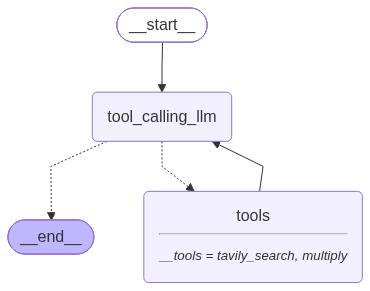

In [ ]:
## StateGrpah - Graph API
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State): ## state class we have previously defined at the start of this notebook.
    return {"messages" : [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


## Connecting the edges with node
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
        # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
        # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
        tools_condition
)
builder.add_edge("tools", "tool_calling_llm") ## replace the END

## compile with graph

graph= builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

## from the below output we can see thet the llm can make multiple tool call using react agent

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_56ee84dc-594b-4652-a22f-a69d41f0c3d5)
 Call ID: fc_56ee84dc-594b-4652-a22f-a69d41f0c3d5
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "October underscored our commitment to AI innovation, as we released one frontier model globally and announced our next one just two weeks later. After rolling out Gemini 4 Argon — a frontier reasoning model — to develope